# Detection data

<!-- markdownlint-disable MD033-->
<div class="page-subtitle">
Prepare image-level object annotations for model training
</div>
<!-- markdownlint-enable MD033 -->

---

## 1. Motivation

A detection {term}`annotation <Annotation>` is more work to produce than a classification label, but less work than a segmentation {term}`mask <Mask>`: you draw one rectangle per object, rather than assigning one label to the whole image or tracing every pixel. Getting the annotation format right, and checking it visually, avoids a frustrating failure mode: a model that trains without errors but learns from silently misaligned or malformed boxes.

---

## 2. Core idea

A classification dataset pairs one image with one label. A detection dataset pairs one image with a *list* of objects, each with its own bounding box and class label, and that list can be empty (an image with no objects at all) or contain dozens of entries (a dense parking lot). This variable-length, per-object structure is what makes detection annotation formats look different from anything you may used in L04 or L05.

For detection, every relevant object needs its own {term}`Annotation`:

```text
image_001.jpg
    ├── vehicle → box
    ├── vehicle → box
    ├── ship    → box
    └── ship    → box
```

A detection dataset therefore links each image with **zero or more object-level labels**. This makes annotation quality a major part of the modelling workflow.

---

## 3. Formats and the benchmark dataset

### A. {abbr}`COCO (Common Objects in Context)` and {abbr}`YOLO (You Only Look Once)` annotation formats

Two annotation formats cover most detection datasets you will encounter:

- **{term}`COCO Format`** stores all annotations for a dataset in a single JSON file containing image metadata, category definitions, and a list of annotation entries.

A simplified example of the JSON file looks like this:

```json
{
  "images": [
    {
      "id": 1,
      "file_name": "image_001.jpg",
      "width": 512,
      "height": 512
    }
  ],
  "categories": [
    {
      "id": 1,
      "name": "vehicle"
    }
  ],
  "annotations": [
    {
      "id": 101,
      "image_id": 1,
      "category_id": 1,
      "bbox": [120, 80, 35, 22]
    }
  ]
}
```

For a COCO detection annotation, the box is typically represented as: `(x, y, width, height)` in absolute pixel coordinates. The central JSON structure makes COCO convenient when one image contains many objects and classes. The `geoai` training workflow used later in this lesson works with COCO-style annotations.

- **{term}`YOLO` format** uses one plain-text file per image. Each line describes one object as `class_id center_x center_y width height`, with coordinates normalized to the range 0 to 1 relative to the image dimensions. For example:

```text
0 0.52 0.41 0.08 0.05
0 0.68 0.56 0.07 0.04
```

A companion file maps class IDs to class names. It is lightweight and easy to generate or edit with basic scripting. This format is lightweight and easy to inspect with basic scripts.

```{warning}
COCO and YOLO do not use the same bounding-box representation. Converting formats requires both the correct coordinate convention and the correct image dimensions.
```

None of these formats is universally "better." COCO's single-file structure is convenient for dataset management and is what you will use in this lesson; YOLO's per-image text files are convenient for lightweight, script-based workflows. If a package or pre-trained model expects a specific format, that constraint usually decides the choice for you.

### B. The NWPU-VHR-10 benchmark

The practical workflow uses the {term}`NWPU-VHR-10` dataset, a widely used benchmark for object detection in very-high-resolution remote sensing imagery. It contains 800 images: 650 "positive" images with at least one annotated object, and 150 "negative," background-only images. It covers 10 object classes: airplane, ship, storage tank, baseball diamond, tennis court, basketball court, ground track field, harbor, bridge, and vehicle, annotated in COCO format. The dataset is useful for teaching because it includes multiple classes, different object sizes, relatively dense object clusters, visually different scene contexts, a manageable dataset size for experimentation.

First import the package and download the archive.

In [4]:
import os
import geoai
from pathlib import Path

DATA_DIR = Path("data/raw")
DATA_DIR.mkdir(parents=True, exist_ok=True)

url = "https://data.source.coop/giuz/sds320/L06/data/NWPU-VHR-10.zip"
data_dir = geoai.download_file(url, output_path=str(DATA_DIR / Path(url).name))

print(f"Dataset directory: {data_dir}")
print(f"Contents: {os.listdir(data_dir)}")

for i, name in enumerate(geoai.NWPU_VHR10_CLASSES):
    print(f"  {i}: {name}")

Dataset directory: data/raw/NWPU-VHR-10
Contents: ['train_annotations.json', 'positive_image_set', 'README.md', 'ground_truth', 'val_annotations.json', 'negative_image_set', 'annotations.json']
  0: background
  1: airplane
  2: ship
  3: storage_tank
  4: baseball_diamond
  5: tennis_court
  6: basketball_court
  7: ground_track_field
  8: harbor
  9: bridge
  10: vehicle


`geoai.download_file()` downloads and extracts the archive, returning the path to the extracted directory. `geoai.NWPU_VHR10_CLASSES` is a plain Python list with the 10 class names plus a `background` class at index 0, which most detection architectures need as an explicit class.

The `geoai.prepare_nwpu_vhr10()` function splits the 650 positive images into training and validation sets and writes separate COCO-format annotation files for each split:

In [5]:
splits = geoai.prepare_nwpu_vhr10(
    data_dir,
    val_split=0.2,
    seed=42,
)

print(f"Images directory: {splits['images_dir']}")
print(f"Number of classes: {splits['num_classes']}")

print(f"Training images: {len(splits['train_image_ids'])}")
print(f"Validation images: {len(splits['val_image_ids'])}")

Images directory: data/raw/NWPU-VHR-10/positive_image_set
Number of classes: 11
Training images: 509
Validation images: 128


`val_split=0.2` reserves 20% of the positive images for the evaluation set you will use on the mAP page. `seed=42` makes the split reproducible: rerunning this cell gives you the same training and validation images every time, which matters if you want to compare results across different runs or architectures fairly, exactly the concern raised on the previous page.

### C. Visually checking annotations

Before training anything, look at a sample of annotated images. This catches misaligned boxes, mislabeled classes, or a corrupted download before you waste time on a training run.

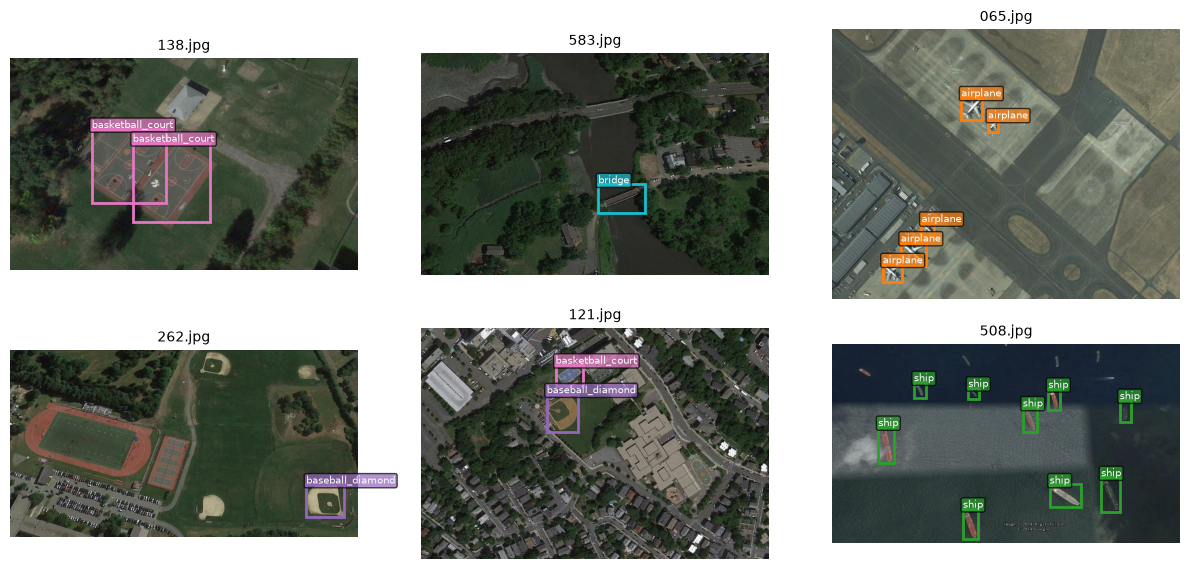

In [6]:
import matplotlib.cm as cm
import matplotlib.pyplot as plt

if not hasattr(cm, "get_cmap"):
    cm.get_cmap = plt.get_cmap

geoai.visualize_coco_annotations(
    annotations_path=splits["annotations_path"],
    images_dir=splits["images_dir"],
    num_samples=6,
    random=True,
    seed=1,
    cols=3,
    figsize=(12, 6),
)

Each sampled image is shown with its ground-truth bounding boxes overlaid, color-coded by class. If you see boxes that clearly do not enclose the objects they claim to, or objects with no box at all, treat that as a data problem to resolve before training, not something a model will simply learn around.

```{admonition} This step is beneficial
:class: important
Skipping visual annotation checks is one of the most common causes of a detector that trains "successfully" but performs poorly. A five-minute visual check is far cheaper than a wasted training run.
```

---

## 4. Python reactivation

`splits` is a Python dictionary, and `splits["images_dir"]`, `splits["train_image_ids"]`, and so on retrieve specific values from it by key, the same pattern you used for function outputs in L04 and L05. `len()` on `splits["train_image_ids"]` counts the items in that list, giving you the training set size without needing to inspect the annotation file directly.

---

## 5. Common pitfalls

- **Ignoring negative (background-only) images.** They matter for teaching a model what "no object here" looks like; do not filter them out without a specific reason.
- **Skipping the visual check because the code ran without errors.** A script with no errors can still produce a dataset with systematically wrong annotations, for example boxes shifted by a tiling offset.
- **Mixing annotation formats without conversion.** If you combine your own labeled data with a benchmark dataset, make sure both are actually in the same format before training; a subtly wrong parser will fail silently rather than raising an error.
- **Not fixing a random seed for your own train/validation split.** Without one, you cannot reproduce your exact split later, which makes debugging and fair architecture comparisons (from the previous page) much harder.

---

## 6. Mini task

`prepare_nwpu_vhr10(data_dir, val_split=0.2, seed=42)` splits the 650 positive NWPU-VHR-10 images. Without running any code, estimate how many images should end up in the training set and how many in the validation set. Then check your estimate against the printed counts in the code cell above.

:::{dropdown} Sample solution
:class: note

With `val_split=0.2`, 20% of 650 images, 130 images, are held out for validation, and the remaining 80%, 520 images, form the training set. Small differences from this exact split are possible depending on how the function handles rounding, but your estimate should land close to this 520 / 130 division.
:::

---

## 7. Key takeaways

- Detection annotations pair each image with a variable-length list of bounding boxes and class labels, unlike the fixed, single-label structure of classification.
- COCO format centralizes annotations in one JSON file; YOLO format uses one normalized text file per image. `geoai`'s detection pipeline uses COCO format.
- NWPU-VHR-10 provides 650 annotated images across 10 classes, plus 150 background-only images, in COCO format.
- Visually checking a sample of annotations before training is a fast, worthwhile step that catches data problems early.
- The training and validation splits you create here, with a fixed seed, carry directly into the next page.